In [1]:
#Import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


In [2]:
#Load the dataset
df=pd.read_csv(r"combined_data_1.txt", header=None, names=['Cust_Id','Rating'],usecols=[0,1])
# df=pd.read_csv(r"combined_data_1.txt", header=None, names=['Cust_Id','Rating'],usecols=[0,1])

df.head()

,Cust_Id,Rating
0,1:,NaN
1,1488844,3.0
2,822109,5.0
3,885013,4.0
4,30878,4.0


## EDA

In [3]:
#Check the overall information of the data.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24058263 entries, 0 to 24058262
Data columns (total 2 columns):
 #   Column   Dtype  
---  ------   -----  
 0   Cust_Id  object 
 1   Rating   float64
dtypes: float64(1), object(1)
memory usage: 367.1+ MB


In [4]:
df = df.sample(n=1_000_000, random_state=42)  # Randomly select 1 million rows


In [5]:
#Check the shape of the data.
# df_sample.shape

In [6]:
#Count the number of ratings given by customers.
ratings_count=pd.DataFrame(df['Rating'].value_counts().sort_index(ascending=True))
ratings_count

,count
Rating,
1.0,46555
2.0,101387
3.0,286968
4.0,336658
5.0,228232


In [7]:
#Calculate how many movies we are having on our dataset.
movie_count=df.isnull().sum()[1]
movie_count

200

In [8]:
# Get the customer count without NaN values (as it will contain unique values of movie id also)
customer_count=df['Cust_Id'].nunique() - movie_count
customer_count

283637

In [9]:
# Aggregate count of rating
Total_ratings_count=ratings_count.sum()[0]
Total_ratings_count

999800

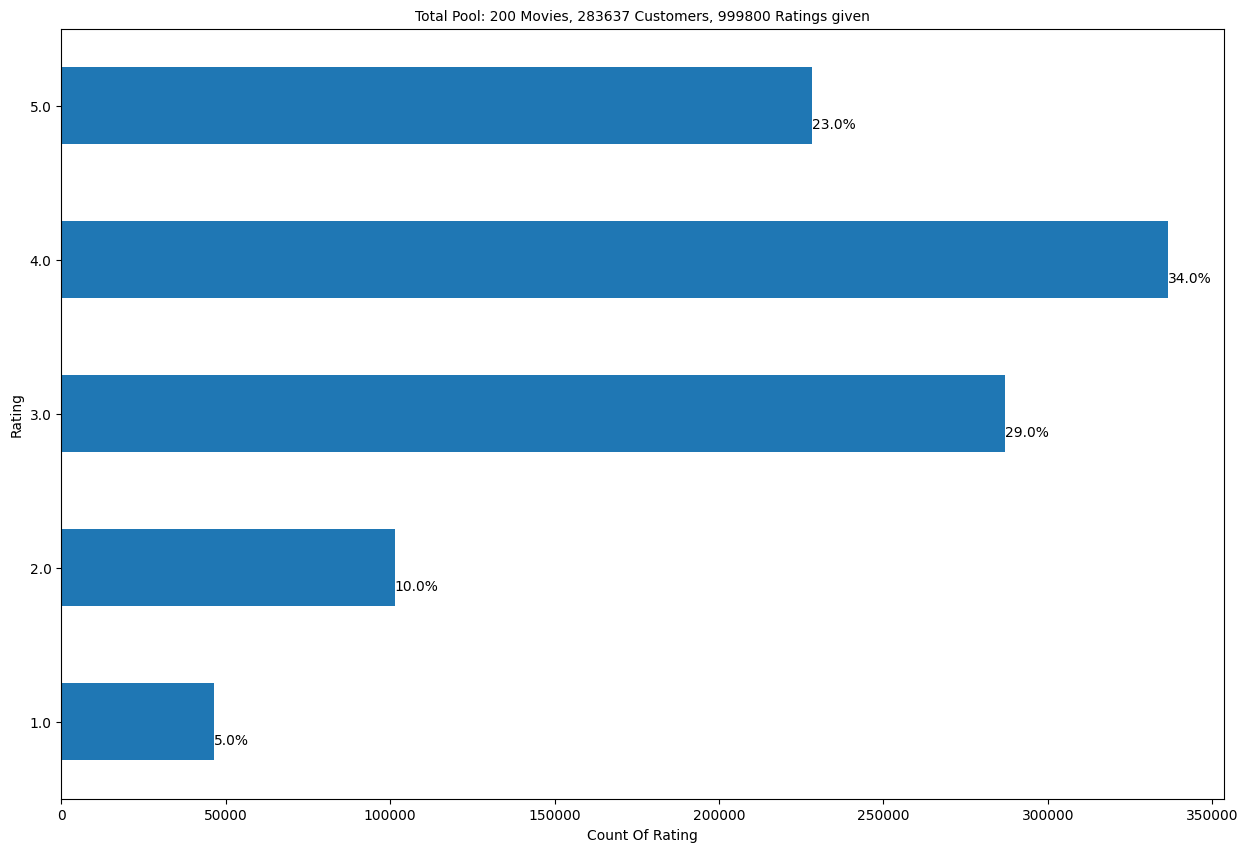

In [10]:
#Visualize the Ratings with the help of bar plot.

ax=ratings_count.plot(kind='barh', legend=False, figsize=(15,10))
plt.title(f"Total Pool: {movie_count} Movies, {customer_count} Customers, {Total_ratings_count} Ratings given", fontsize=10)
plt.xlabel("Count Of Rating")
plt.ylabel("Rating")

for i in ax.patches:
  percentage=i.get_width() / Total_ratings_count * 100
  ax.text(i.get_width(), i.get_y() + 0.1, \
          f"{round(percentage,0)}%", fontsize=10, color='black')

plt.ticklabel_format(style='plain',axis='x')
plt.show()

In [11]:
df['Rating'].isnull()

22281427    False
12009376    False
17766168    False
20134498    False
15393678    False
            ...  
10095863    False
3312861     False
21425523    False
17983415    False
10692642    False
Name: Rating, Length: 1000000, dtype: bool

In [12]:
# Add another that will have movie id.
# Get all the index where null value is present beacuse it is representing the movie id.

df_nan=pd.DataFrame(df['Rating'].isnull())
df_nan=df_nan[df_nan['Rating']==True]
df_nan

,Rating
17755377,True
13787159,True
9981497,True
11519824,True
2792599,True
...,...
7468614,True
9987613,True
5040638,True
20447811,True


In [13]:
#Check the shape
df_nan.shape

(200, 1)

In [14]:
# Now we will reset the index and make it a column
df_nan.reset_index(inplace=True)
df_nan

,index,Rating
0,17755377,True
1,13787159,True
2,9981497,True
3,11519824,True
4,2792599,True
...,...,...
195,7468614,True
196,9987613,True
197,5040638,True
198,20447811,True


## Data PreProcessing

In [15]:
# Now we will numpy array that will contain 1 for values between 0-547, 2 for values betwn 548-693  and so on.
# Creating an empty list.
movie_np=[]

# Initializing the value of movie id which will increase with each iteration.
movie_id=1

# Creating a loop to iterate over consecutive pairs of indices.
for i, j  in zip(df_nan['index'][1:], df_nan['index'][:-1]):

  # Creating a numpy array filled with the current movie ID
  temp=np.full((1,i-j-1), movie_id)   # Subtracting 1 from j means for e.g. i= 0 and j=548, in the index of 548 there
                                      # is a new movie id present so we will exclude that and fill upto 547 likewise
                                      # it will do for the rest.


  # Appending the numpy array to the movie_np list
  movie_np = np.append(movie_np,temp)

  # Incrementing the movie ID for the next iteration
  movie_id += 1

# Handling the last record separately

last_record = np.full((1, len(df) - df_nan.iloc[-1,0]-1), movie_id)

# Appending the last record to the movie_np list
movie_np = np.append(movie_np, last_record)

# Printing the movie numpy array and its length
print(f"Movie Numpy: {movie_np}")
print(f"Length: {len(movie_np)}")


ValueError: negative dimensions are not allowed

In [ ]:
#Here we are removing all the places where null values (movies id) are present and keeping them in a separate column named as 'Movie_Id'

# Get all the data except the null values.
df=df[pd.notnull(df['Rating'])]

# Create a new column named 'Movie_Id'
df['Movie_Id']=movie_np.astype(int)

# Change the data type of 'Cust_Id' column to integer.
df['Cust_Id']=df['Cust_Id'].astype(int)

print('Now the dataset looks like: ')
df.iloc[:548]

Now the dataset looks like: 


,Cust_Id,Rating,Movie_Id
1,1488844,3.0,1
2,822109,5.0,1
3,885013,4.0,1
4,30878,4.0,1
5,823519,3.0,1
...,...,...,...
544,1403184,3.0,1
545,1535440,4.0,1
546,1426604,4.0,1
547,1815755,5.0,1


In [ ]:
# Its time to load our second dataset which contains the Movie Title and Genre.

df_title = pd.read_csv(r"movies.csv",header=0,names=['Movie_Id','Title','Genres'],on_bad_lines='skip')


df_title.head()

,Movie_Id,Title,Genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [ ]:
df_title.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27278 entries, 0 to 27277
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Movie_Id  27278 non-null  int64 
 1   Title     27278 non-null  object
 2   Genres    27278 non-null  object
dtypes: int64(1), object(2)
memory usage: 639.5+ KB


In [ ]:
# Now we are going to split the genres by converting them into string and then replacing '|' with ','.
df_title['Genres']=df_title['Genres'].str.split('|')
df_title

,Movie_Id,Title,Genres
0,1,Toy Story (1995),"[Adventure, Animation, Children, Comedy, Fantasy]"
1,2,Jumanji (1995),"[Adventure, Children, Fantasy]"
2,3,Grumpier Old Men (1995),"[Comedy, Romance]"
3,4,Waiting to Exhale (1995),"[Comedy, Drama, Romance]"
4,5,Father of the Bride Part II (1995),[Comedy]
...,...,...,...
27273,131254,Kein Bund für's Leben (2007),[Comedy]
27274,131256,"Feuer, Eis & Dosenbier (2002)",[Comedy]
27275,131258,The Pirates (2014),[Adventure]
27276,131260,Rentun Ruusu (2001),[(no genres listed)]


In [ ]:
# This function will transform each element of a list like column into a separate row,
# replicating the index values for each new row created  from the lists.
# for e.g. toy story movie was having 5 genres and was rated 547 times so after explode it will become 547*5 i.e. 2735 rows.

expanded_data=df_title.explode('Genres')
expanded_data

,Movie_Id,Title,Genres
0,1,Toy Story (1995),Adventure
0,1,Toy Story (1995),Animation
0,1,Toy Story (1995),Children
0,1,Toy Story (1995),Comedy
0,1,Toy Story (1995),Fantasy
...,...,...,...
27275,131258,The Pirates (2014),Adventure
27276,131260,Rentun Ruusu (2001),(no genres listed)
27277,131262,Innocence (2014),Adventure
27277,131262,Innocence (2014),Fantasy


In [ ]:
# Checking the unique genres.

expanded_data['Genres'].unique()

array(['Adventure', 'Animation', 'Children', 'Comedy', 'Fantasy',
       'Romance', 'Drama', 'Action', 'Crime', 'Thriller', 'Horror',
       'Mystery', 'Sci-Fi', 'IMAX', 'Documentary', 'War', 'Musical',
       'Western', 'Film-Noir', '(no genres listed)'], dtype=object)

In [ ]:
# As we can see in genres column there is 'IMAX' and 'no genres listed' are present as genres which are not relevant.
# So we will filter them out.

expanded_data=expanded_data[(expanded_data['Genres']!='IMAX') & (expanded_data['Genres']!='(no genres listed)')]

In [ ]:
# Verifying if the irrelevant genres are gone or not.

expanded_data['Genres'].unique()

array(['Adventure', 'Animation', 'Children', 'Comedy', 'Fantasy',
       'Romance', 'Drama', 'Action', 'Crime', 'Thriller', 'Horror',
       'Mystery', 'Sci-Fi', 'Documentary', 'War', 'Musical', 'Western',
       'Film-Noir'], dtype=object)

In [ ]:
# Merge both the df and expanded_data  beased on Movie ID.

merged_df=pd.merge(df,expanded_data,on='Movie_Id',how='inner')
merged_df.head()

,Cust_Id,Rating,Movie_Id,Title,Genres
0,1081737,5.0,1073,Willy Wonka & the Chocolate Factory (1971),Children
1,1081737,5.0,1073,Willy Wonka & the Chocolate Factory (1971),Comedy
2,1081737,5.0,1073,Willy Wonka & the Chocolate Factory (1971),Fantasy
3,1081737,5.0,1073,Willy Wonka & the Chocolate Factory (1971),Musical
4,2119555,5.0,2795,National Lampoon's Vacation (1983),Comedy


46714936, 5)

In [ ]:
merged_df.shape

(1942980, 5)

547 rows × 5 columns

In [ ]:
merged_df[merged_df['Title']=='Toy Story (1995)']

,Cust_Id,Rating,Movie_Id,Title,Genres
6835,2565654,5.0,1,Toy Story (1995),Adventure
6836,2565654,5.0,1,Toy Story (1995),Animation
6837,2565654,5.0,1,Toy Story (1995),Children
6838,2565654,5.0,1,Toy Story (1995),Comedy
6839,2565654,5.0,1,Toy Story (1995),Fantasy
...,...,...,...,...,...
1929985,411705,4.0,1,Toy Story (1995),Adventure
1929986,411705,4.0,1,Toy Story (1995),Animation
1929987,411705,4.0,1,Toy Story (1995),Children
1929988,411705,4.0,1,Toy Story (1995),Comedy


In [ ]:
merged_df[merged_df.isnull().any(axis=1)]

,Cust_Id,Rating,Movie_Id,Title,Genres


# 1. Find out the list of most popular and liked genre.

In [ ]:
from IPython.core.display import display, HTML

# Calculate the average rating for each genre (most liked)
liked_genres = merged_df.groupby('Genres')['Rating'].mean().sort_values(ascending=False).reset_index()
most_liked_genres=liked_genres.head()

# Create HTML for the most liked genres
html_most_liked_genres = """
<h2>Most Liked Genres (by Average Rating)</h2>
<table border="1">
<tr>
    <th>Genre</th>
    <th>Average Rating</th>
</tr>
"""

for index, row in most_liked_genres.iterrows():
    html_most_liked_genres += f"<tr><td>{row['Genres']}</td><td>{row['Rating']:.2f}</td></tr>"

html_most_liked_genres += "</table>"

# Calculate the count of ratings for each genre (most popular)
most_popular_genres = merged_df.groupby('Genres')['Rating'].count().sort_values(ascending=False).reset_index()
most_popular_genres = most_popular_genres.rename(columns={'Rating': 'Rating_Count'}).head()

# Create HTML for the most popular genres
html_most_popular_genres = """
<h2>Most Popular Genres (by Rating Count)</h2>
<table border="1">
<tr>
    <th>Genre</th>
    <th>Rating Count</th>
</tr>
"""

for index, row in most_popular_genres.iterrows():
    html_most_popular_genres += f"<tr><td>{row['Genres']}</td><td>{row['Rating_Count']}</td></tr>"

html_most_popular_genres += "</table>"

# Display the HTML
display(HTML(html_most_liked_genres))
display(HTML(html_most_popular_genres))


Genre,Average Rating
Musical,3.74
Horror,3.73
Animation,3.72
Adventure,3.69
Children,3.67


Genre,Rating Count
Drama,476172
Comedy,352078
Romance,160840
Thriller,138435
Crime,121747


# 3. Find what Genre Movies have received the best and worst ratings based on User Rating

In [ ]:
Best_genre_movie=liked_genres
Best_genre_movie.head()

,Genres,Rating
0,Musical,3.735727
1,Horror,3.729767
2,Animation,3.723120
3,Adventure,3.685366
4,Children,3.669889


In [ ]:
Worst_genre_movie= liked_genres.sort_values(by='Rating',ascending=True).reset_index(drop=True)
Worst_genre_movie.head()

,Genres,Rating
0,Documentary,3.518209
1,War,3.523484
2,Mystery,3.525499
3,Crime,3.538551
4,Thriller,3.543511


# Now let us perform Data Cleaning.

In [ ]:
# Now we will remove all the movies with less ratings and Users that have given less ratings by setting benchmark.

df_movie_summary=merged_df.groupby('Movie_Id')['Rating'].agg(['count','mean'])
df_movie_summary

,count,mean
Movie_Id,,
1,120,3.791667
2,15,4.800000
3,148,3.770270
4,24,2.500000
5,55,3.690909
...,...,...
4495,52,3.576923
4496,1038,3.731214
4497,172,2.441860


In [ ]:
# Now we will create Benchmark for keeping movies that are being rated more than 70% of the time.

movie_benchmark=round(df_movie_summary['count'].quantile(0.7),0)
print(f"Movie Benchmark: {movie_benchmark}")

#Now we will create a list of Movie ID values where movies rating count is less than 1799.

drop_movie_list = df_movie_summary[df_movie_summary['count'] <  movie_benchmark].index
drop_movie_list

Movie Benchmark: 138.0


Index([   1,    2,    4,    5,    6,    7,    9,   10,   11,   12,
       ...
       4484, 4485, 4486, 4487, 4489, 4491, 4494, 4495, 4498, 4499],
      dtype='int32', name='Movie_Id', length=3073)

6	153	3.333333
7	195	4.066667
8	21	4.000000
10	49	3.346939
25	4	3.500000

In [17]:
# Now we  will remove all the users who are in-active or given few ratings.

df_cust_summary = merged_df.groupby('Cust_Id') ['Rating'].agg(['count','mean'])
df_cust_summary

NameError: name 'merged_df' is not defined

In [73]:
#Now set the benchmark for in active customers.

cust_benchmark= round(df_cust_summary['count'].quantile(0.7),0)
print(f"Customer Benchmark: {cust_benchmark}", "\n")

# Now create a list of 'Cust_Id" which i has given rating below 52 are considered i-active.

drop_cust_list =  df_cust_summary[(df_cust_summary['count'] < cust_benchmark)].index
drop_cust_list

Customer Benchmark: 8.0 



Index([     10,      42,      59,      87,      94,      97,     116,     126,
           158,     169,
       ...
       2649323, 2649328, 2649335, 2649370, 2649376, 2649384, 2649388, 2649401,
       2649426, 2649429],
      dtype='int32', name='Cust_Id', length=198177)

In [74]:
# Check the original shape of the data.
print("The original shape of DataFrame has: ", merged_df.shape, "shape")

The original shape of DataFrame has:  (1942980, 5) shape


In [75]:
# Now we will drop all the Movies and Customers that are below the benchmark.

merged_df = merged_df[~merged_df['Movie_Id'].isin(drop_movie_list)]  # '~' symbol will not include the true values coming from isin()

merged_df = merged_df[~merged_df['Cust_Id'].isin(drop_cust_list)]

print(f"After trimming the shape is: {merged_df.shape} ")


After trimming the shape is: (1229371, 5) 


In [76]:
merged_df.head()

,Cust_Id,Rating,Movie_Id,Title,Genres
0,1081737,5.0,1073,Willy Wonka & the Chocolate Factory (1971),Children
1,1081737,5.0,1073,Willy Wonka & the Chocolate Factory (1971),Comedy
2,1081737,5.0,1073,Willy Wonka & the Chocolate Factory (1971),Fantasy
3,1081737,5.0,1073,Willy Wonka & the Chocolate Factory (1971),Musical
4,2119555,5.0,2795,National Lampoon's Vacation (1983),Comedy


In [16]:
import pandas as pd

# Load the .txt file (assuming tab-separated values)
merged_df = pd.read_csv("merged_data_1M.txt", sep="\t")

# Save it as a .csv file
merged_df.to_csv("merged_data_1M.csv", sep=",", index=False)


In [17]:
import pandas as pd

# Load the dataset
merged_data = pd.read_csv('merged_data_1M.csv')

# Calculate the number of unique users and unique movies
unique_users = merged_data['Cust_Id'].nunique()
unique_movies = merged_data['Movie_Id'].nunique()

# Print the results
print(f"Number of unique users: {unique_users}")
print(f"Number of unique movies: {unique_movies}")

Number of unique users: 85299
Number of unique movies: 1319


In [19]:
import pandas as pd

# Load the dataset
merged_data = pd.read_csv('merged_data_1M.csv')

# Check the minimum values of Cust_Id and Movie_Id
min_cust_id = merged_data['Cust_Id'].min()
min_movie_id = merged_data['Movie_Id'].min()

# Verify if they are 1-indexed
is_cust_id_1_indexed = min_cust_id == 1
is_movie_id_1_indexed = min_movie_id == 1

# Print the results
print(f"Minimum Cust_Id: {min_cust_id}")
print(f"Is Cust_Id 1-indexed? {is_cust_id_1_indexed}")
print(f"Minimum Movie_Id: {min_movie_id}")
print(f"Is Movie_Id 1-indexed? {is_movie_id_1_indexed}")

Minimum Cust_Id: 6
Is Cust_Id 1-indexed? False
Minimum Movie_Id: 3
Is Movie_Id 1-indexed? False


In [20]:
# Extract only the required columns for SVD
svd_data = merged_data[['Cust_Id', 'Movie_Id', 'Rating']]

# Save the DataFrame to a CSV file
svd_data.to_csv("merged_data_1M_three_cols.csv", index=False)

print("SVD data saved successfully.")


SVD data saved successfully.


In [77]:
merged_df.to_csv("merged_data_1M.txt", sep="\t", index=False)


In [78]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1229371 entries, 0 to 1942976
Data columns (total 5 columns):
 #   Column    Non-Null Count    Dtype  
---  ------    --------------    -----  
 0   Cust_Id   1229371 non-null  int32  
 1   Rating    1229371 non-null  float64
 2   Movie_Id  1229371 non-null  int32  
 3   Title     1229371 non-null  object 
 4   Genres    1229371 non-null  object 
dtypes: float64(1), int32(2), object(2)
memory usage: 46.9+ MB


In [79]:
pip install scikit-surprise

^C
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 25.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


     ---------------------------------------- 0.0/154.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/154.4 kB ? eta -:--:--
     -- ------------------------------------- 10.2/154.4 kB ? eta -:--:--
     ------- ----------------------------- 30.7/154.4 kB 262.6 kB/s eta 0:00:01
     ------------------- ----------------- 81.9/154.4 kB 573.4 kB/s eta 0:00:01
     ------------------------------------ 154.4/154.4 kB 924.3 kB/s eta 0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for scikit-surprise: filename=scikit_surprise-1.1.4-cp312-cp312-win_amd64.whl size=1294627 sha256=5fe577a13ab78d83bc6d401f837fd3cbe064147d37ce4541d063155201d3c3df
  Stored in directory: c:\users

In [42]:
#Import the libararies required for model building.
from scipy.sparse import csr_matrix
from surprise import Reader, Dataset, SVD
from surprise.model_selection import cross_validate,train_test_split


In [43]:
# Help us to read the dataset for SVD algorithm
reader=Reader()

In [44]:
# This line creates a Surprise Dataset object ('surprise_data') containing the data from the DataFrame

surprise_data=Dataset.load_from_df(merged_df[['Cust_Id', 'Movie_Id', 'Rating']], reader)

In [45]:
# Creating an instance of the SVD algorithm
# This initializes the SVD algorithm, which will be used for collaborative filtering-based recommendation

svd=SVD()

# Performing cross-validation on the Surprise Dataset object (surprise_data) using the SVD algorithm
# This evaluates the performance of the SVD algorithm using 3-fold cross-validation
# 'RMSE' (Root Mean Squared Error) and 'MAE' (Mean Absolute Error) are the evaluation metrics used
# The 'cv' parameter specifies the number of folds for cross-validation, which is set to 3
# The 'verbose' parameter controls whether to print progress messages during cross-validation

cross_validate(svd,surprise_data,measures=['RMSE', 'MAE'], cv=3, verbose=True)

Evaluating RMSE, MAE of algorithm SVD on 3 split(s).

                  Fold 1  Fold 2  Fold 3  Mean    Std     
RMSE (testset)    0.7382  0.7394  0.7384  0.7387  0.0005  
MAE (testset)     0.5625  0.5635  0.5626  0.5629  0.0005  
Fit time          491.14  516.47  560.64  522.75  28.72   
Test time         283.27  215.61  326.85  275.25  45.77   


{'test_rmse': array([0.73818747, 0.73937417, 0.73839007]),
 'test_mae': array([0.56252848, 0.56351767, 0.56257175]),
 'fit_time': (491.13892889022827, 516.4730784893036, 560.6446604728699),
 'test_time': (283.26898860931396, 215.61495447158813, 326.8535807132721)}

> *RMSE measures the square root of the average squared differences between predicted and actual ratings. Lower values indicate better accuracy. The mean RMSE across the three folds is 0.7385, with a standard deviation of 0.0005, indicating very consistent performance across the folds.*

> *MAE measures the average absolute differences between predicted and actual ratings. Like RMSE, lower values indicate better accuracy. The mean MAE across the three folds is 0.5630, with a standard deviation of 0.0003, showing consistent performance.*

> *Fit time indicates the time taken to train the SVD model on each fold. The mean fit time is approximately 502.05 seconds, with some variability (standard deviation of 27.26 seconds) across the folds.*

> *Test time indicates the time taken to evaluate the SVD model on the test set of each fold. The mean test time is approximately 230.18 seconds, with more variability (standard deviation of 37.07 seconds) compared to the fit time.*

In [46]:
# So first we take user 712664 and we try to recommend some movies based on the 5 star rated movies.

user_712664= merged_df[(merged_df['Cust_Id']==712664) & (merged_df['Rating']==5)]
user_712664=user_712664.set_index('Movie_Id')

user_712664

,Cust_Id,Rating,Title,Genres
Movie_Id,,,,
3,712664,5.0,Grumpier Old Men (1995),Comedy
3,712664,5.0,Grumpier Old Men (1995),Romance
79,712664,5.0,"Juror, The (1996)",Drama
79,712664,5.0,"Juror, The (1996)",Thriller
175,712664,5.0,Kids (1995),Drama
...,...,...,...,...
4384,712664,5.0,Lumumba (2000),Drama
4392,712664,5.0,Alice (1990),Comedy
4392,712664,5.0,Alice (1990),Drama


In [47]:
# Using the build_full_trainset method of the Surprise Dataset object (surprise_data)
# This method constructs a training set from the entire input data, suitable for training a model

train_set=surprise_data.build_full_trainset()

# Fitting the SVD algorithm (svd) to the training set (train_set)
svd.fit(train_set)

# Create Model that finds the best suited Movie for one  user in every genre.

In [48]:
# Define a function to find the Top Movies for each User in every Genre.

def get_top_movies_per_genre(user_id, data ,algo):
    genres = data['Genres'].unique()
    top_movies = []
    
    # Get the set of movie IDs that the user has rated
    rated_movie_ids = set(data[data['Cust_Id'] == user_id]['Movie_Id'])
    avg_ratings = data.groupby('Movie_Id')['Rating'].mean().to_dict()
    
    for genre in genres:
        # Filter movies of the given genre
        genre_movie = data[data['Genres']==genre]['Movie_Id'].unique()
        
        # Using list comprehension to store only the movies that the user has not rated means not watched yet.
        unrated_genre_movies = [movie_id for movie_id in genre_movie if movie_id not in rated_movie_ids]
        
        # Predict ratings for the user for all movies in this genre.
        predictions = [algo.predict(user_id, movie_id) for movie_id in unrated_genre_movies]
        
        # Sort predictions by estimated score
        predictions.sort(key=lambda x: x.est, reverse=True)
        
        # Get top movies for this genre if there are predictions available.
        if predictions:
            # Select the top movie prediction
            top_movie = predictions[0]
            
            # Get the title of the top movie
            movie_title= data[data['Movie_Id']==top_movie.iid]['Title'].iloc[0]

            avg_rating = avg_ratings.get(top_movie.iid, "No Rating")  # Get the average rating
            
            # Append top movie details to the list
            top_movies.append({'Movie_Id': top_movie.iid,
                               'Title': movie_title,
                               'Rating': avg_rating,
                               'Genre': genre,
                               'Estimated Score': top_movie.est})
            
            
    return pd.DataFrame(top_movies)

In [49]:
import random

# Assuming 'merged_df' is your DataFrame and it has a 'user_id' column
user_ids = merged_df['Cust_Id'].unique()
User_Id = random.choice(user_ids)

# The function returns a DataFrame containing the top movies per genre based on estimated scores from the SVD algorithm
top_movies_per_genre = get_top_movies_per_genre(User_Id, merged_df, svd)

# Sorting the DataFrame by 'Estimated Score' column in descending order
top_movies_per_genre = top_movies_per_genre.sort_values(by='Estimated Score', ascending=False).reset_index(drop=True)

# Displaying the DataFrame containing the top movies per genre
print(f"\033[1m Best Suited Movie For {User_Id} In Every Genre: ")
top_movies_per_genre.head(50)


 Best Suited Movie For 1834827 In Every Genre: 


,Movie_Id,Title,Rating,Genre,Estimated Score
0,2585,"Lovers of the Arctic Circle, The (Los Amantes ...",3.942005,Romance,4.938202
1,2585,"Lovers of the Arctic Circle, The (Los Amantes ...",3.942005,Drama,4.938202
2,2613,Night of the Comet (1984),4.047501,Comedy,4.908640
3,2613,Night of the Comet (1984),4.047501,Horror,4.908640
4,2613,Night of the Comet (1984),4.047501,Sci-Fi,4.908640
5,3150,"War Zone, The (1999)",3.991328,Thriller,4.879867
6,1770,B. Monkey (1998),3.884891,Crime,4.838577
7,432,City Slickers II: The Legend of Curly's Gold (...,3.951923,Adventure,4.806020
8,432,City Slickers II: The Legend of Curly's Gold (...,3.951923,Western,4.806020
9,160,Congo (1995),2.982574,Action,4.661279


# Checking if the user rated movies are present in the recommended movies.


In [50]:
#Select the User
user=merged_df[merged_df['Cust_Id']==User_Id]

#Find the movies rated by user.
user_rated_movies=user['Movie_Id']

#Find the movies recommended to the user by the algorithm.
recommended_movies=top_movies_per_genre['Movie_Id']

#Check if the recommended movies are present in the user rated movies.
recommended_movies[recommended_movies.isin(user_rated_movies)]



Series([], Name: Movie_Id, dtype: int64)

# Alternate method to predict movies for each User in every Genre

In [51]:
# Remove all the movies that are already rated by the User.
unrated_movies=set(merged_df['Movie_Id'].unique()) - set(user_rated_movies)

In [52]:
# Convert the set into dataframe for further process.
unrated_movies=pd.DataFrame(list(unrated_movies), columns=['Movie_Id'])
unrated_movies.head()

,Movie_Id
0,4097
1,4098
2,3
3,4100
4,4103


In [53]:
# Now Predict the Estimation score for the User using SVD's Predict function.
unrated_movies['Estimated_Score']=unrated_movies['Movie_Id'].apply(lambda x: svd.predict(User_Id,x).est)
unrated_movies=unrated_movies.sort_values(by='Estimated_Score', ascending=False)
unrated_movies

,Movie_Id,Estimated_Score
802,2585,4.938202
808,2613,4.908640
934,3150,4.879867
576,1770,4.838577
229,432,4.806020
...,...,...
474,1289,1.445839
666,2113,1.395700
1101,3745,1.309237
106,4290,1.282104


In [54]:
unrated_movies

,Movie_Id,Estimated_Score
802,2585,4.938202
808,2613,4.908640
934,3150,4.879867
576,1770,4.838577
229,432,4.806020
...,...,...
474,1289,1.445839
666,2113,1.395700
1101,3745,1.309237
106,4290,1.282104


In [55]:
# Merge the title df with  to see the names of the movies and sort by Estimated Score.
unrated_movies=pd.merge(unrated_movies,expanded_data, on='Movie_Id')

# Get the movie with the highest estimated score for each genre
recommended_movies=unrated_movies.loc[unrated_movies.groupby('Genres')['Estimated_Score'].idxmax()]
recommended_movies.sort_values(by='Estimated_Score', ascending=False, inplace=True)
recommended_movies.reset_index(drop=True, inplace=True)
recommended_movies

,Movie_Id,Estimated_Score,Title,Genres
0,2585,4.938202,"Lovers of the Arctic Circle, The (Los Amantes ...",Romance
1,2585,4.938202,"Lovers of the Arctic Circle, The (Los Amantes ...",Drama
2,2613,4.908640,Night of the Comet (1984),Horror
3,2613,4.908640,Night of the Comet (1984),Sci-Fi
4,2613,4.908640,Night of the Comet (1984),Comedy
5,3150,4.879867,"War Zone, The (1999)",Thriller
6,1770,4.838577,B. Monkey (1998),Crime
7,432,4.806020,City Slickers II: The Legend of Curly's Gold (...,Western
8,432,4.806020,City Slickers II: The Legend of Curly's Gold (...,Adventure
9,160,4.661279,Congo (1995),Mystery
